# EpiHydra — quick LoRA training run (1–2 epochs)

Runs the single-clock age-prediction pipeline end to end for a couple of epochs, using the functions in `epihydra.py`, `train.py` and `run.py` instead of notebook-local class definitions.

| Step | Comes from |
|---|---|
| Model-dir check, run ID | `run.validate_model_dir`, `run.build_run_id` |
| Vocab, backbone, model | `epihydra.VocabWrapper`, `load_backbone`, `AgePredictor` |
| Splits, scaler, masking, loaders | `train.build_dataloaders` |
| Train / evaluate | `train.train_one_epoch`, `train.evaluate` |

The LoRA config, optimiser and scheduler are set up inline, copied from `run.main()`, because `run.py` does not expose them as functions.

## 1. Configuration

In [178]:
from pathlib import Path

# Folder that contains epihydra.py, train.py and run.py
SRC_DIR    = Path(".")

MODEL_DIR  = Path("/work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/medium/")
DATA_PATH  = Path("/work/gr-fe/bryan/EpiHydra/data/02_processed/GSE40279/methylation.pkl")

NUM_EPOCHS   = 25
BATCH_SIZE   = 16       # as in the original notebook (run.py default is 128)
NUM_WORKERS  = 0
RANDOM_STATE = 42

# Masking. None -> epihydra.DEFAULT_MASK_WEIGHTS.
# {"uniform": 1.0} reproduces the original fully random masking.
MASK_RATIO   = 0.0
MASK_WEIGHTS = None

# Model / LoRA / optimiser: run.py defaults
NUM_HEADS    = 4
N_QUERIES    = 1
DROPOUT      = 0.0
LORA_R       = 8
LORA_ALPHA   = 16
LR_HEAD      = 3e-3
LR_LORA      = 1e-3
WEIGHT_DECAY = 0.00
CLIP_GRAD    = 1.0      # passed through, but clipping is commented out in train.train_one_epoch

# Cosine schedule length. Kept at the full-run value so these epochs see the
# same learning rate as the first epochs of a real run. Set to NUM_EPOCHS to
# decay fully within this notebook instead.
SCHED_T_MAX  = 50

## 2. Imports

In [179]:
import warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
warnings.filterwarnings("ignore", message=".*flash_attn.*")
warnings.filterwarnings("ignore", message=".*nested tensor.*")

import sys, json, pickle, time
from types import SimpleNamespace

import numpy as np
import torch
import torch.nn as nn
from peft import LoraConfig, get_peft_model

sys.path.insert(0, str(SRC_DIR.resolve()))

from epihydra import VocabWrapper, AgePredictor, load_backbone, DEFAULT_MASK_WEIGHTS, build_dataloaders, train_one_epoch, evaluate

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## 3. Model directory and pretrain config

In [180]:
# methylgpt model config
with open(MODEL_DIR / "args.json", "r") as f:
    pretrain_config = json.load(f)

# ── Build vocab ──────────────────────────────────────────────────
vocab = VocabWrapper(MODEL_DIR / "vocab.json" , pretrain_config["n_hvg"])

# ── model_args — passed through to precompute_tokens ────────────
model_args = {
    "n_hvg"      : pretrain_config["n_hvg"],
    "mask_ratio" : 0.0,
    "mask_value" : -1,   # -1, defined in VocabWrapper
}

## 4. Data

`build_dataloaders` aligns CpGs to the vocab order, splits 70/15/15, fits the age scaler on the training split, computes the variance ranks and builds the three loaders. Check the *Present / Missing* line it prints.

In [181]:
with open(DATA_PATH, "rb") as f:
    data = pickle.load(f)

#data['meta'] = data['meta'].sample(n=20, random_state=42).reset_index(drop=True)
#data['CpG'] = data['CpG'].loc[:, data['meta']["ID"].tolist()]

#data['meta']['age'] = [50 for i in range(data['meta']['age'].shape[0])]
#print(data['meta'].head())

splits = build_dataloaders(
    data         = data,
    vocab        = vocab,
    train_ratio  = 0.7,
    valid_ratio  = 0.15,
    test_ratio   = 0.15,
    mask_ratio   = MASK_RATIO,
    mask_weights = MASK_WEIGHTS,
    batch_size   = BATCH_SIZE,
    num_workers  = NUM_WORKERS,
    random_state = RANDOM_STATE,
    verbose      = True,
)
train_loader = splits["train_loader"]
valid_loader = splits["valid_loader"]
test_loader  = splits["test_loader"]
scaler       = splits["scaler"]

print(f"Mask weights : {MASK_WEIGHTS or DEFAULT_MASK_WEIGHTS}")
print(f"Age scaler   : {scaler.data_min_[0]:.1f} – {scaler.data_max_[0]:.1f} years")

Samples in meta : 656
Samples in CpG  : 656
Common samples  : 656
Samples after NaN drop : 656

Vocab CpGs : 49,159 | Present : 45,309 (92.2%) | Missing : 3,850
ℹ  Missing CpGs → NaN → padded during tokenisation.

Train : 459 | Valid : 98 | Test : 99
Age range (train) : 21.0 – 101.0 years
ℹ  Scaler fitted on training ages.
ℹ  CpG variance ranks computed (49,159 probes). Mask modes: uniform=90%, high_var=10%, low_var=0%
✓ Data loaded and ready.

Mask weights : {'uniform': 0.9, 'low_variance': 0.0, 'high_variance': 0.1}
Age scaler   : 21.0 – 101.0 years


/work/gr-fe/bryan/EpiHydra/epihydra/epihydra.py:125: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = np.nanvar(X, axis=0)                  # (n_cpgs,) — NaN where all-NaN probe


## 5. Model + LoRA

In [182]:
backbone  = load_backbone(MODEL_DIR / "medium-best_model_epoch6.pt", vocab, pretrain_config)
pad_id    = vocab.vocab["<pad>"]

age_model = AgePredictor(
    backbone,
    embed_dim = pretrain_config["layer_size"],
    pad_id    = pad_id,
    num_heads = NUM_HEADS,
    dropout   = DROPOUT,
    n_queries = N_QUERIES,
).to(device)

lora_config = LoraConfig(
    r              = LORA_R,
    lora_alpha     = LORA_ALPHA,
    target_modules = ["Wqkv", "out_proj", "linear1", "linear2"],
    lora_dropout   = 0.0,
)
age_model.backbone = get_peft_model(age_model.backbone, lora_config)
age_model.backbone.print_trainable_parameters()

n_total     = sum(p.numel() for p in age_model.parameters())
n_trainable = sum(p.numel() for p in age_model.parameters() if p.requires_grad)
print(f"Total params     : {n_total:,}")
print(f"Trainable params : {n_trainable:,}")

/work/gr-fe/bryan/miniconda3/envs/methylgpt/lib/python3.11/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer was not TransformerEncoderLayer
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


Loaded all params from /work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/medium/medium-best_model_epoch6.pt
trainable params: 129,032 || all params: 15,551,754 || trainable%: 0.8297
Total params     : 15,848,715
Trainable params : 425,993


## 6. Optimiser, scheduler, loss

In [183]:
optimizer = torch.optim.AdamW([
    {"params": [p for p in age_model.backbone.parameters() if p.requires_grad], "lr": LR_LORA},
    {"params": age_model.head.parameters(), "lr": LR_HEAD},
], weight_decay=WEIGHT_DECAY)

scheduler  = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=300, eta_min=1e-6)
criterion  = nn.MSELoss()
scaler_amp = torch.cuda.amp.GradScaler()

## 7. Optional: one-batch sanity check

Pushes a single training batch through the model without taking an optimiser step. It reports the masked fraction, checks that predictions and targets have the same shape, and lists trainable parameters that receive no gradient. Skip this cell if you only want the training run.

In [184]:
age_model.train()
gene_ids, masked_vals, _, _, ages_norm, _ = next(iter(train_loader))
gene_ids, masked_vals = gene_ids.to(device), masked_vals.to(device)
target = ages_norm.to(device).squeeze()

LOSS_SCALE = 2.0 ** 16   # same factor GradScaler starts training with

optimizer.zero_grad()
with torch.cuda.amp.autocast():
    pred = age_model(gene_ids, masked_vals)
    loss = criterion(pred, target)
(loss.float() * LOSS_SCALE).backward()

for tag in ["lora_A", "lora_B", "head"]:
    params = [p for n, p in age_model.named_parameters() if p.requires_grad and tag in n]
    n_none = sum(p.grad is None for p in params)
    n_zero = sum(p.grad is not None and p.grad.abs().sum() == 0 for p in params)
    norms  = [p.grad.float().norm().item() / LOSS_SCALE for p in params if p.grad is not None]
    print(f"{tag:<7} tensors={len(params):3d} | None={n_none:3d} | all-zero={n_zero:3d} | "
          f"max grad norm={max(norms) if norms else float('nan'):.2e}")

optimizer.zero_grad()   # discard: no step is taken here

lora_A  tensors= 26 | None=  0 | all-zero= 26 | max grad norm=0.00e+00
lora_B  tensors= 26 | None=  0 | all-zero=  0 | max grad norm=6.34e-02
head    tensors= 11 | None=  0 | all-zero=  0 | max grad norm=inf


## 8. Train

In [185]:
import numpy as np
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

bb = load_backbone(MODEL_DIR / "medium-best_model_epoch6.pt", vocab, pretrain_config).to(device).eval()

@torch.no_grad()
def pooled_features(loader):
    feats, ages = [], []
    for gene_ids, _, target_vals, a, _, _ in loader:
        gene_ids, vals = gene_ids.to(device), target_vals.to(device)
        mask, cap = gene_ids.eq(pad_id), {}
        hook = bb.transformer_encoder.register_forward_hook(lambda m, i, o: cap.update(h=o))
        with torch.autocast("cuda", dtype=torch.bfloat16):
            bb(gene_ids, vals, src_key_padding_mask=mask, batch_labels=None)
        hook.remove()
        keep = (~mask).unsqueeze(-1).float()
        feats.append(((cap["h"].float() * keep).sum(1) / keep.sum(1)).cpu())
        ages.extend(a.numpy())
    return torch.cat(feats).numpy(), np.array(ages)

X_tr, y_tr = pooled_features(splits["train_loader"])
X_va, y_va = pooled_features(splits["valid_loader"])

probe = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))).fit(X_tr, y_tr)
print(f"Ridge on frozen pooled features, valid MAE : {np.abs(probe.predict(X_va) - y_va).mean():.2f} yrs")
print(f"Predict the training mean,      valid MAE : {np.abs(y_va - y_tr.mean()).mean():.2f} yrs")

Loaded all params from /work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/medium/medium-best_model_epoch6.pt
Ridge on frozen pooled features, valid MAE : 7.35 yrs
Predict the training mean,      valid MAE : 11.97 yrs


In [11]:
import time
import torch.nn as nn

y_mu, y_sd = y_tr.mean(), y_tr.std()          # train targets standardised: MSE of the mean = 1.0
d = pretrain_config["layer_size"]

class AttnBNHead(nn.Module):
    """Attention pooling -> BatchNorm across the batch -> Linear. Zero query = uniform attention at init."""
    def __init__(self, d, num_heads=4):
        super().__init__()
        self.query = nn.Parameter(torch.zeros(1, 1, d))
        self.attn  = nn.MultiheadAttention(d, num_heads, batch_first=True)
        self.bn, self.out = nn.BatchNorm1d(d), nn.Linear(d, 1)
    def forward(self, h, pad_mask):
        att, w = self.attn(self.query.expand(h.shape[0], -1, -1), h, h, key_padding_mask=pad_mask)
        with torch.autocast("cuda", enabled=False):
            return self.out(self.bn(att[:, 0].float())).squeeze(-1), w

class MeanBNHead(nn.Module):
    """Mean over non-pad positions -> BatchNorm -> Linear (the ridge probe, trained by SGD)."""
    def __init__(self, d):
        super().__init__()
        self.bn, self.out = nn.BatchNorm1d(d), nn.Linear(d, 1)
    def forward(self, h, pad_mask):
        keep   = (~pad_mask).unsqueeze(-1).to(h.dtype)
        pooled = (h * keep).sum(1, dtype=torch.float32) / keep.sum(1, dtype=torch.float32)
        with torch.autocast("cuda", enabled=False):
            return self.out(self.bn(pooled)).squeeze(-1), None

heads = {"attention+BN": AttnBNHead(d).to(device), "meanpool+BN": MeanBNHead(d).to(device)}
opts  = {k: torch.optim.Adam(h.parameters(), lr=1e-3) for k, h in heads.items()}

def backbone_hidden(gene_ids, vals):
    mask, cap = gene_ids.eq(pad_id), {}
    hook = bb.transformer_encoder.register_forward_hook(lambda m, i, o: cap.update(h=o))
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
        bb(gene_ids, vals, src_key_padding_mask=mask, batch_labels=None)
    hook.remove()
    return cap["h"], mask

@torch.no_grad()
def valid_mae(loader):
    for h in heads.values():
        h.eval()
    preds, ys = {k: [] for k in heads}, []
    for gene_ids, _, vals, a, _, _ in loader:
        hid, mask = backbone_hidden(gene_ids.to(device), vals.to(device))
        with torch.autocast("cuda", dtype=torch.bfloat16):
            for k, h in heads.items():
                preds[k].append(h(hid, mask)[0].float().cpu())
        ys.append(a)
    y = torch.cat(ys).numpy()
    return {k: np.abs(torch.cat(p).numpy() * y_sd + y_mu - y).mean() for k, p in preds.items()}

ridge_mae = np.abs(probe.predict(X_va) - y_va).mean()
mean_mae  = np.abs(y_va - y_tr.mean()).mean()
print(f"Reference | ridge {ridge_mae:.2f} yrs | predict-mean {mean_mae:.2f} yrs\n")

N_EPOCHS = 10
for epoch in range(1, N_EPOCHS + 1):
    t0 = time.time()
    for h in heads.values():
        h.train()
    losses, n_batches, attn_ratio = {k: 0.0 for k in heads}, 0, []

    for gene_ids, _, vals, a, _, _ in splits["train_loader"]:
        if len(a) < 2:                          # BatchNorm needs more than one sample
            continue
        hid, mask = backbone_hidden(gene_ids.to(device), vals.to(device))
        target = torch.as_tensor((a.numpy() - y_mu) / y_sd, dtype=torch.float32, device=device)
        for k, h in heads.items():
            with torch.autocast("cuda", dtype=torch.bfloat16):
                pred, w = h(hid, mask)
            loss = nn.functional.mse_loss(pred.float(), target)
            opts[k].zero_grad(set_to_none=True)
            loss.backward()
            opts[k].step()
            losses[k] += loss.item()
            if w is not None:                   # max attention weight relative to uniform
                n_real = (~mask).sum(1, keepdim=True).float()
                attn_ratio.append((w[:, 0].float().max(1).values * n_real[:, 0]).mean().item())
        n_batches += 1

    mae = valid_mae(splits["valid_loader"])
    print(f"Epoch {epoch:2d} | "
          + " | ".join(f"{k}: train {losses[k]/n_batches:.3f}, valid {mae[k]:.2f} yrs" for k in heads)
          + f" | max attn = {np.mean(attn_ratio):.1f}x uniform | {time.time() - t0:.0f}s")

Reference | ridge 7.40 yrs | predict-mean 12.50 yrs

Epoch  1 | attention+BN: train 0.734, valid 25.34 yrs | meanpool+BN: train 0.723, valid 9.71 yrs | max attn = 1.0x uniform | 415s
Epoch  2 | attention+BN: train 0.581, valid 11.90 yrs | meanpool+BN: train 0.612, valid 9.20 yrs | max attn = 1.3x uniform | 412s
Epoch  3 | attention+BN: train 0.543, valid 12.08 yrs | meanpool+BN: train 0.572, valid 8.97 yrs | max attn = 7.8x uniform | 412s
Epoch  4 | attention+BN: train 0.536, valid 13.44 yrs | meanpool+BN: train 0.561, valid 8.87 yrs | max attn = 10.3x uniform | 413s


KeyboardInterrupt: 

In [12]:
@torch.no_grad()
def recalibrate_bn(head, loader, n_batches=20):
    """Re-estimate BatchNorm running stats with the current weights (cumulative average)."""
    head.bn.reset_running_stats()
    head.bn.momentum = None
    head.train()
    for i, (gene_ids, _, vals, _, _, _) in enumerate(loader):
        if i >= n_batches:
            break
        hid, mask = backbone_hidden(gene_ids.to(device), vals.to(device))
        with torch.autocast("cuda", dtype=torch.bfloat16):
            head(hid, mask)
    head.bn.momentum = 0.1

In [ ]:
N_EPOCHS = 10
for epoch in range(1, N_EPOCHS + 1):
    t0 = time.time()
    for h in heads.values():
        h.train()
    losses, n_batches, attn_ratio = {k: 0.0 for k in heads}, 0, []

    for gene_ids, _, vals, a, _, _ in splits["train_loader"]:
        if len(a) < 2:                          # BatchNorm needs more than one sample
            continue
        hid, mask = backbone_hidden(gene_ids.to(device), vals.to(device))
        target = torch.as_tensor((a.numpy() - y_mu) / y_sd, dtype=torch.float32, device=device)
        for k, h in heads.items():
            with torch.autocast("cuda", dtype=torch.bfloat16):
                pred, w = h(hid, mask)
            loss = nn.functional.mse_loss(pred.float(), target)
            opts[k].zero_grad(set_to_none=True)
            loss.backward()
            opts[k].step()
            losses[k] += loss.item()
            if w is not None:                   # max attention weight relative to uniform
                n_real = (~mask).sum(1, keepdim=True).float()
                attn_ratio.append((w[:, 0].float().max(1).values * n_real[:, 0]).mean().item())
        n_batches += 1

    recalibrate_bn(heads["attention+BN"], splits["train_loader"])
    mae = valid_mae(splits["valid_loader"])
    print(f"Epoch {epoch:2d} | "
          + " | ".join(f"{k}: train {losses[k]/n_batches:.3f}, valid {mae[k]:.2f} yrs" for k in heads)
          + f" | max attn = {np.mean(attn_ratio):.1f}x uniform | {time.time() - t0:.0f}s")

Epoch  1 | attention+BN: train 0.519, valid 8.24 yrs | meanpool+BN: train 0.548, valid 8.80 yrs | max attn = 13.3x uniform | 453s
Epoch  2 | attention+BN: train 0.523, valid 8.50 yrs | meanpool+BN: train 0.540, valid 8.71 yrs | max attn = 18.6x uniform | 451s


In [61]:
history = []
best_mae, best_epoch = float("inf"), 0

for epoch in range(1, 300 + 1):
    t0 = time.time()

    train_loss = train_one_epoch(
        age_model, train_loader, optimizer, criterion, scaler_amp, device, CLIP_GRAD,
    )
    scheduler.step()

    valid_mae, valid_preds, valid_labels, _ = evaluate(age_model, valid_loader, scaler, device)

    if valid_mae < best_mae:
        best_mae, best_epoch = valid_mae, epoch

    history.append({"epoch": epoch, "train_loss": train_loss, "valid_mae": valid_mae})
    print(
        f"Epoch {epoch}/{NUM_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Valid MAE: {valid_mae:.2f} yrs | "
        f"Valid pred std: {valid_preds.std():.2f} (labels {valid_labels.std():.2f}) | "
        f"LR: {scheduler.get_last_lr()[0]:.2e} | "
        f"{time.time() - t0:.0f}s"
    )

print(f"\nBest valid MAE: {best_mae:.2f} years (epoch {best_epoch})")

Epoch 1/25 | Train loss: 0.0001 | Valid MAE: 17.63 yrs | Valid pred std: 2.46 (labels 9.29) | LR: 1.00e-03 | 2s
Epoch 2/25 | Train loss: 0.6334 | Valid MAE: 17.69 yrs | Valid pred std: 2.41 (labels 9.29) | LR: 1.00e-03 | 2s
Epoch 3/25 | Train loss: 0.6352 | Valid MAE: 17.70 yrs | Valid pred std: 2.43 (labels 9.29) | LR: 1.00e-03 | 2s
Epoch 4/25 | Train loss: 0.6339 | Valid MAE: 3.33 yrs | Valid pred std: 5.96 (labels 9.29) | LR: 1.00e-03 | 2s
Epoch 5/25 | Train loss: 0.0832 | Valid MAE: 13.81 yrs | Valid pred std: 5.09 (labels 9.29) | LR: 9.99e-04 | 2s
Epoch 6/25 | Train loss: 0.0367 | Valid MAE: 17.76 yrs | Valid pred std: 2.97 (labels 9.29) | LR: 9.99e-04 | 2s
Epoch 7/25 | Train loss: 0.1265 | Valid MAE: 17.22 yrs | Valid pred std: 1.90 (labels 9.29) | LR: 9.99e-04 | 2s
Epoch 8/25 | Train loss: 0.1319 | Valid MAE: 15.18 yrs | Valid pred std: 1.35 (labels 9.29) | LR: 9.98e-04 | 2s
Epoch 9/25 | Train loss: 0.1053 | Valid MAE: 13.03 yrs | Valid pred std: 0.96 (labels 9.29) | LR: 9.98e-0

KeyboardInterrupt: 

In [ ]:
import time

N_STEPS, LOG_EVERY = 400, 25
USE_BF16  = torch.cuda.is_bf16_supported()
amp_dtype = torch.bfloat16 if USE_BF16 else torch.float16

gene_ids, _, target_vals, ages, ages_norm, _ = next(iter(train_loader))
gene_ids = gene_ids.to(device)
values   = target_vals.to(device)              # unmasked values
target   = ages_norm.to(device).view(-1)
baseline = target.var(unbiased=False).item()   # MSE of always predicting the mean
print(f"batch {len(target)} | mean-prediction MSE = {baseline:.4f}")

print("backbone dropout from pretrain config:", pretrain_config.get("dropout", 0.0))

def fresh_model(seed=0):
    torch.manual_seed(seed)
    bb = load_backbone(MODEL_DIR / "tiny-best_model_epoch10.pt", vocab, pretrain_config)
    m = AgePredictor(bb, embed_dim=pretrain_config["layer_size"], pad_id=pad_id,
                     num_heads=NUM_HEADS, dropout=0.0, n_queries=N_QUERIES).to(device)
    m.backbone = get_peft_model(m.backbone, LoraConfig(
        r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=0.1,
        target_modules=["Wqkv", "out_proj", "linear1", "linear2"]))
    return m.to(device)

def run_variant(name, lr_lora, backbone_dropout, lr_head=3e-3, n_steps=600, log_every=50):
    m = fresh_model()
    lora_params = [p for p in m.backbone.parameters() if p.requires_grad]
    groups = [{"params": m.head.parameters(), "lr": lr_head}]
    if lr_lora > 0:
        groups.append({"params": lora_params, "lr": lr_lora})
    else:
        for p in lora_params:
            p.requires_grad_(False)          # backbone fully frozen (and cheaper: no backbone backward)
    opt = torch.optim.AdamW(groups, weight_decay=0.0)

    m.train()
    if not backbone_dropout:
        m.backbone.eval()                    # dropout off; LoRA still receives gradients

    hist, t0 = [], time.time()
    for step in range(1, n_steps + 1):
        with torch.autocast("cuda", dtype=torch.bfloat16):
            pred = m(gene_ids, values)
        loss = nn.functional.mse_loss(pred.float(), target)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        hist.append(loss.item() / baseline)
        if step % log_every == 0:
            print(f"[{name}] step {step:4d} | loss/baseline (avg last {log_every}) "
                  f"{np.mean(hist[-log_every:]):.3f} | pred std {pred.float().std():.3f} | "
                  f"{time.time() - t0:.0f}s")
    del m, opt
    torch.cuda.empty_cache()
    return hist

results = {}
#results["A1 LoRA frozen, dropout off"] = run_variant("A1", lr_lora=0,    backbone_dropout=False)
#results["A2 LoRA frozen, dropout on"]  = run_variant("A2", lr_lora=0,    backbone_dropout=True)
#results["A3 LoRA 1e-4,  dropout off"]  = run_variant("A3", lr_lora=1e-4, backbone_dropout=False)
results["A4 LoRA 1e-3,  dropout off"]  = run_variant("A4", lr_lora=1e-3, backbone_dropout=False)

batch 16 | mean-prediction MSE = 0.0671
backbone dropout from pretrain config: 0.1
Loaded all params from /work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/tiny/tiny-best_model_epoch10.pt
[A4] step   50 | loss/baseline (avg last 50) 1.015 | pred std 0.119 | 100s
[A4] step  100 | loss/baseline (avg last 50) 0.209 | pred std 0.254 | 199s
[A4] step  150 | loss/baseline (avg last 50) 0.035 | pred std 0.279 | 299s
[A4] step  200 | loss/baseline (avg last 50) 0.018 | pred std 0.272 | 398s
[A4] step  250 | loss/baseline (avg last 50) 0.018 | pred std 0.272 | 498s
[A4] step  300 | loss/baseline (avg last 50) 0.016 | pred std 0.273 | 597s
[A4] step  350 | loss/baseline (avg last 50) 0.011 | pred std 0.260 | 697s
[A4] step  400 | loss/baseline (avg last 50) 0.008 | pred std 0.276 | 797s
[A4] step  450 | loss/baseline (avg last 50) 0.007 | pred std 0.264 | 896s
[A4] step  500 | loss/baseline (avg last 50) 0.009 | pred std 0.268 | 996s


In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
for k, h in results.items():
    ax.plot(np.convolve(h, np.ones(20) / 20, mode="valid"), label=k)
ax.axhline(1.0, ls="--", c="grey", lw=1)
ax.set_yscale("log"); ax.set_xlabel("step"); ax.set_ylabel("loss / mean-baseline (smoothed)")
ax.legend(frameon=False); plt.show()

In [20]:
N_STEPS, LOG_EVERY = 400, 25
USE_BF16  = torch.cuda.is_bf16_supported()
amp_dtype = torch.bfloat16 if USE_BF16 else torch.float16

gene_ids, _, target_vals, ages, ages_norm, _ = next(iter(train_loader))
gene_ids = gene_ids.to(device)
values   = target_vals.to(device)              # unmasked values
target   = ages_norm.to(device).view(-1)
baseline = target.var(unbiased=False).item()   # MSE of always predicting the mean
print(f"batch {len(target)} | mean-prediction MSE = {baseline:.4f}")

opt = torch.optim.AdamW([
    {"params": [p for p in age_model.backbone.parameters() if p.requires_grad], "lr": 1e-3},
    {"params": age_model.head.parameters(), "lr": 3e-3},
], weight_decay=0.0)
gscaler = torch.cuda.amp.GradScaler(enabled=not USE_BF16)

age_model.train()
for step in range(1, N_STEPS + 1):
    with torch.autocast("cuda", dtype=amp_dtype):
        pred = age_model(gene_ids, values)
    loss = nn.functional.mse_loss(pred.float(), target)
    opt.zero_grad(set_to_none=True)
    gscaler.scale(loss).backward()
    gscaler.step(opt)
    gscaler.update()
    if step == 1 or step % LOG_EVERY == 0:
        print(f"step {step:4d} | loss {loss.item():.5f} ({loss.item()/baseline:.2f}x mean-baseline) | "
              f"pred std {pred.float().std():.4f} (target {target.std():.4f}) | "
              f"amp scale {gscaler.get_scale() if not USE_BF16 else 1:.0f}")

batch 16 | mean-prediction MSE = 0.0596
step    1 | loss 0.17980 (3.02x mean-baseline) | pred std 0.0305 (target 0.2521) | amp scale 1
step   25 | loss 0.06184 (1.04x mean-baseline) | pred std 0.0145 (target 0.2521) | amp scale 1
step   50 | loss 0.05195 (0.87x mean-baseline) | pred std 0.0661 (target 0.2521) | amp scale 1
step   75 | loss 0.05322 (0.89x mean-baseline) | pred std 0.0841 (target 0.2521) | amp scale 1
step  100 | loss 0.05669 (0.95x mean-baseline) | pred std 0.0416 (target 0.2521) | amp scale 1
step  125 | loss 0.05430 (0.91x mean-baseline) | pred std 0.0691 (target 0.2521) | amp scale 1
step  150 | loss 0.05577 (0.94x mean-baseline) | pred std 0.0860 (target 0.2521) | amp scale 1
step  175 | loss 0.03418 (0.57x mean-baseline) | pred std 0.1304 (target 0.2521) | amp scale 1
step  200 | loss 0.05916 (0.99x mean-baseline) | pred std 0.0115 (target 0.2521) | amp scale 1
step  225 | loss 0.05585 (0.94x mean-baseline) | pred std 0.0567 (target 0.2521) | amp scale 1
step  250 

KeyboardInterrupt: 

In [21]:
from epihydra import AttentionPoolingHead

captured = {}
hook = age_model.backbone.transformer_encoder.register_forward_hook(
    lambda m, i, o: captured.update(hidden=o))
age_model.eval()
with torch.no_grad(), torch.autocast("cuda", dtype=amp_dtype):
    age_model.backbone(gene_ids, values,
                       src_key_padding_mask=gene_ids.eq(pad_id), batch_labels=None)
hook.remove()
hidden   = captured["hidden"].float().detach()   # (B, seq_len, 64)
pad_mask = gene_ids.eq(pad_id)

head  = AttentionPoolingHead(pretrain_config["layer_size"], NUM_HEADS,
                             dropout=0.0, n_queries=N_QUERIES).to(device)
opt_h = torch.optim.AdamW(head.parameters(), lr=3e-3, weight_decay=0.0)
for step in range(1, 2001):
    pred, attn = head(hidden, key_padding_mask=pad_mask)
    loss = nn.functional.mse_loss(pred, target)
    opt_h.zero_grad(); loss.backward(); opt_h.step()
    if step == 1 or step % 200 == 0:
        print(f"step {step:4d} | loss/baseline {loss.item()/baseline:.3f} | "
              f"pred std {pred.std():.4f} | max attn weight {attn.max():.2e} "
              f"(uniform = {1/(~pad_mask).sum(1).float().mean():.2e})")

step    1 | loss/baseline 1.753 | pred std 0.1428 | max attn weight 2.04e-05 (uniform = 2.03e-05)
step  200 | loss/baseline 0.793 | pred std 0.0921 | max attn weight 3.27e-05 (uniform = 2.03e-05)
step  400 | loss/baseline 0.186 | pred std 0.2043 | max attn weight 1.49e-04 (uniform = 2.03e-05)
step  600 | loss/baseline 0.146 | pred std 0.2150 | max attn weight 4.11e-04 (uniform = 2.03e-05)
step  800 | loss/baseline 0.004 | pred std 0.2509 | max attn weight 8.78e-04 (uniform = 2.03e-05)
step 1000 | loss/baseline 0.002 | pred std 0.2514 | max attn weight 1.03e-03 (uniform = 2.03e-05)
step 1200 | loss/baseline 0.001 | pred std 0.2515 | max attn weight 1.14e-03 (uniform = 2.03e-05)
step 1400 | loss/baseline 0.006 | pred std 0.2517 | max attn weight 1.25e-03 (uniform = 2.03e-05)
step 1600 | loss/baseline 0.001 | pred std 0.2525 | max attn weight 1.34e-03 (uniform = 2.03e-05)
step 1800 | loss/baseline 0.003 | pred std 0.2518 | max attn weight 1.42e-03 (uniform = 2.03e-05)
step 2000 | loss/bas

In [22]:
keep   = (~pad_mask).unsqueeze(-1).float()
pooled = (hidden * keep).sum(1) / keep.sum(1)                 # (B, 64)
print(f"pooled: between-sample std {pooled.std(0).mean():.5f} | "
      f"within-vector std {pooled.std(1).mean():.5f}")
z = (pooled - pooled.mean(0)) / (pooled.std(0) + 1e-6)        # standardise each dim across samples

lin   = nn.Linear(z.shape[1], 1).to(device)
opt_l = torch.optim.Adam(lin.parameters(), lr=1e-2)
for step in range(1, 2001):
    loss = nn.functional.mse_loss(lin(z).squeeze(-1), target)
    opt_l.zero_grad(); loss.backward(); opt_l.step()
    if step == 1 or step % 400 == 0:
        print(f"step {step:4d} | loss/baseline {loss.item()/baseline:.4f}")

pooled: between-sample std 0.04989 | within-vector std 0.17035
step    1 | loss/baseline 12.8291
step  400 | loss/baseline 0.1490
step  800 | loss/baseline 0.0133
step 1200 | loss/baseline 0.0010
step 1600 | loss/baseline 0.0001
step 2000 | loss/baseline 0.0000


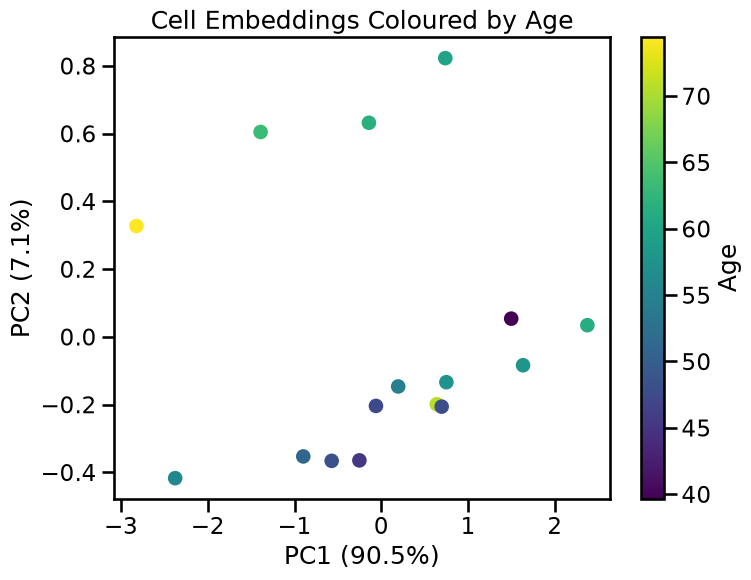

Variance explained by PC1+PC2: 97.5%


In [51]:
def head_features(model, gene_ids, values):
    """Pooled representation the MLP actually sees (before the final layers)."""
    captured = {}
    hook = model.backbone.transformer_encoder.register_forward_hook(
        lambda m, i, o: captured.update(h=o))
    mask = gene_ids.eq(model.pad_id)
    model.backbone(gene_ids, values, src_key_padding_mask=mask, batch_labels=None)
    hook.remove()
    head = model.head
    q = head.query.expand(gene_ids.shape[0], -1, -1)
    att, _ = head.cross_attn(q, captured["h"], captured["h"], key_padding_mask=mask)
    return head.norm(att.mean(1) + q.mean(1))

age_model.eval()
feats, ages_list = [], []
with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
    for gene_ids, _, target_vals, ages, _, _ in train_loader:
        feats.append(head_features(age_model, gene_ids.to(device), target_vals.to(device)).float().cpu())
        ages_list.extend(ages.numpy())
feats = torch.cat(feats).numpy()


from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# PCA on embeddings
pca = PCA(n_components=2)
emb_2d = pca.fit_transform(feats)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(emb_2d[:, 0], emb_2d[:, 1], 
                      c=true_ages_list, cmap='viridis')
plt.colorbar(scatter, label='Age')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.title("Cell Embeddings Coloured by Age")
plt.show()

print(f"Variance explained by PC1+PC2: {pca.explained_variance_ratio_[:2].sum():.1%}")


In [41]:
for g, name in zip(optimizer.param_groups, ["lora", "head"]):
    print(f"{name:4s} lr = {g['lr']:.2e}")

lora_b = [p for n, p in age_model.named_parameters() if "lora_B" in n]
print(f"lora_B total norm: {torch.sqrt(sum((p.float()**2).sum() for p in lora_b)).item():.2e} (0 = LoRA has done nothing)")

lora lr = 5.50e-06
head lr = 5.00e-04
lora_B total norm: 8.19e-03 (0 = LoRA has done nothing)


In [14]:
from scipy.stats import pearsonr
import numpy as np

X = embeddings.numpy()
y = np.array(true_ages_list)

correlations = np.array([
    pearsonr(X[:, i], y)[0]
    for i in range(X.shape[1])
])

print("Maximum absolute correlation:", np.abs(correlations).max())
print("Mean absolute correlation:", np.abs(correlations).mean())
print("Dimensions with |r| > 0.3:", (np.abs(correlations) > 0.3).sum())

Maximum absolute correlation: 0.4082283914065451
Mean absolute correlation: 0.2105674189810734
Dimensions with |r| > 0.3: 11


## 9. Test evaluation

Uses the model as it stands after the last epoch (no checkpoint is saved or reloaded in this notebook).

Test MAE       : 2.85 years
Test R²        : -70.411
Test Pearson r : -1.000


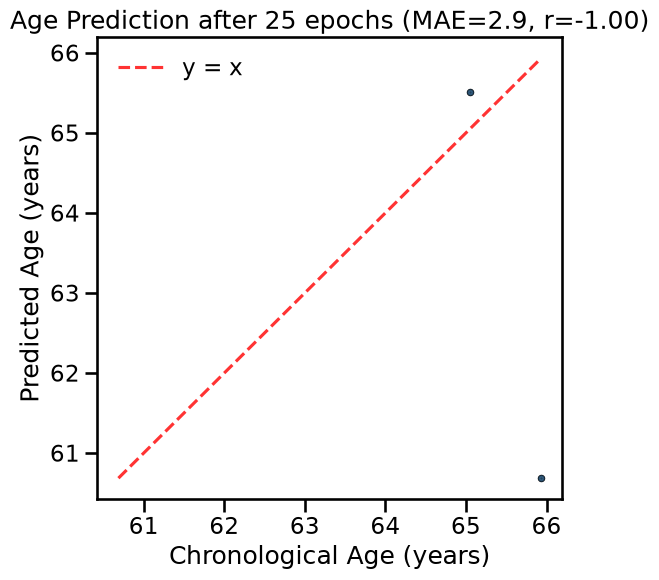

In [63]:
from sklearn.metrics import r2_score
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

test_mae, test_preds, test_labels, test_ids = evaluate(age_model, valid_loader, scaler, device)
test_r2   = r2_score(test_labels, test_preds)
test_r, _ = pearsonr(test_labels, test_preds)

print(f"Test MAE       : {test_mae:.2f} years")
print(f"Test R²        : {test_r2:.3f}")
print(f"Test Pearson r : {test_r:.3f}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(test_labels, test_preds, s=15, c="black", alpha=1.0, zorder=1)
ax.scatter(test_labels, test_preds, s=10, c="steelblue", alpha=0.5, zorder=2)
lims = [min(test_labels.min(), test_preds.min()), max(test_labels.max(), test_preds.max())]
ax.plot(lims, lims, "r--", alpha=0.8, label="y = x")
ax.set_xlabel("Chronological Age (years)")
ax.set_ylabel("Predicted Age (years)")
ax.set_title(f"Age Prediction after {NUM_EPOCHS} epochs (MAE={test_mae:.1f}, r={test_r:.2f})")
ax.legend(frameon=False)
plt.show()